In [2]:
import nibabel as nib
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import nibabel as nib
from nibabel.processing import resample_to_output, resample_from_to
import nibabel.orientations as nio
from skimage.util import montage
from skimage.transform import rotate
from typing import Optional, Tuple
from collections import Counter

In [3]:
p_patients = Path("dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData")
test_patient = "BraTS20_Training_001"

In [4]:
#let's verify if all patients have same pattern of files
def list_files(path : Path) -> list[Path]:
    return [p for p in path.iterdir() if p.is_file()]
test_path = p_patients/test_patient
list_files(test_path)

[WindowsPath('dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_flair.nii'),
 WindowsPath('dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_seg.nii'),
 WindowsPath('dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t1.nii'),
 WindowsPath('dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t1ce.nii'),
 WindowsPath('dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t2.nii')]

#### Let's work on the common folder structure, inspect the files

In [119]:
!pip install git+https://github.com/miykael/gif_your_nifti

  Cloning https://github.com/miykael/gif_your_nifti to c:\users\thaim\appdata\local\temp\pip-req-build-62t6y4xn
  Resolved https://github.com/miykael/gif_your_nifti to commit 55c09c42921f4871cf43f63a303ab420a92a4f03
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py install for gif-your-nifti: started
  Running setup.py install for gif-your-nifti: finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/miykael/gif_your_nifti 'C:\Users\thaim\AppData\Local\Temp\pip-req-build-62t6y4xn'
  DEPRECATION: gif-your-nifti is being installed using the legacy 'setup.py install' method, because it does not have a 'pyproject.toml' and the 'wheel' package is not installed. pip 23.1 will enforce this behaviour change. A possible replacement is to enable the '--use-pep517' option. Discussion can be found at https://github.com/pypa/pip/issues/8559

[notice] A new release of pip available: 22.3.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [133]:
import gif_your_nifti.core as gif2nif
import shutil
from IPython.display import Image  

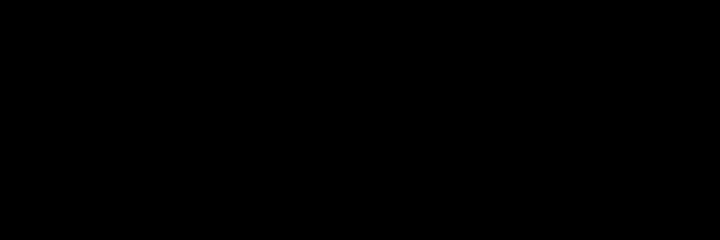

In [137]:
shutil.copy2("dataset/officialDs/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/" + 'BraTS20_Training_001/BraTS20_Training_001_flair.nii', './test_gif_BraTS20_Training_001_flair.nii')
gif2nif.write_gif_normal('./test_gif_BraTS20_Training_001_flair.nii')
Image("./test_gif_BraTS20_Training_001_flair.gif")

In [5]:
def load_nifti(path : Path):
    """
    nii: has header + affine (metadata)
    data: the actual 3D array
    """
    nii = nib.load(str(path))
    data = nii.get_fdata(dtype=np.float32)
    return nii, data

In [6]:
def inspect_volume(name: str, nii):
    data = nii.get_fdata(dtype=np.float32)
    spacing = nii.header.get_zooms()[:3]   # (sx, sy, sz) in mm
    print(f"\n[{name}]")
    print("  shape:", data.shape)
    print("  spacing(mm):", spacing)
    print("  dtype:", data.dtype)
    """
    min/max -> smallest and largest voxel value in the volume
    why do we care ?
    Detect background convention
    - Many MRIs use 0 as background. Some use -1024, some use tiny noise.
    Catch broken scaling
    - If you expect MRI-like values and see min=-3e9, something is wrong.
    Differentiate image vs mask
    - Image: wide range (hundreds or thousands)
    - Mask: tiny discrete range (e.g. {0,1,2,3})

    Example
        min=0, max=2069 → looks like MRI intensity
        min=0, max=3 → almost certainly a segmentation mask
    """
    print("  min/max:", float(np.min(data)), float(np.max(data)))
    """
    mean / std
    What it is
        Average intensity and spread of intensities.
    
    Why you care
        This tells you about intensity distribution, which matters a lot in MRI.
        
    You use it to:
        Detect dataset shift between sources
        Decide normalization strategy
        Catch volumes that are:
            mostly empty
            saturated
            badly preprocessed
    
    Subtle but important
        MRI intensities are not standardized.
        So:
            Different scanners → different mean/std     
            Different sequences → wildly different stats
            
            That’s exactly why you inspect them.
    
    Example
        Dataset A: mean=80, std=180
        Dataset B: mean=400, std=900
            → if you don’t normalize, your model learns scanner identity instead of tumors.
    Do you need it?
        Yes to design preprocessing
        No to log every batch forever
    """
    print("  mean/std:", float(np.mean(data)), float(np.std(data)))
    print("  unique (mask-ish check):", np.unique(data)[:10])



[BraTS20_Training_001_flair.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 625.0
  mean/std: 26.021915435791016 66.76537322998047
  unique (mask-ish check): [ 0. 14. 16. 17. 18. 19. 20. 21. 22. 23.]

[BraTS20_Training_001_seg.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 4.0
  mean/std: 0.05197121575474739 0.35266146063804626
  unique (mask-ish check): [0. 1. 2. 4.]

[BraTS20_Training_001_t1.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 678.0
  mean/std: 53.287132263183594 130.78494262695312
  unique (mask-ish check): [ 0. 25. 27. 30. 31. 32. 33. 34. 35. 36.]

[BraTS20_Training_001_t1ce.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 1845.0
  mean/std: 62.771633

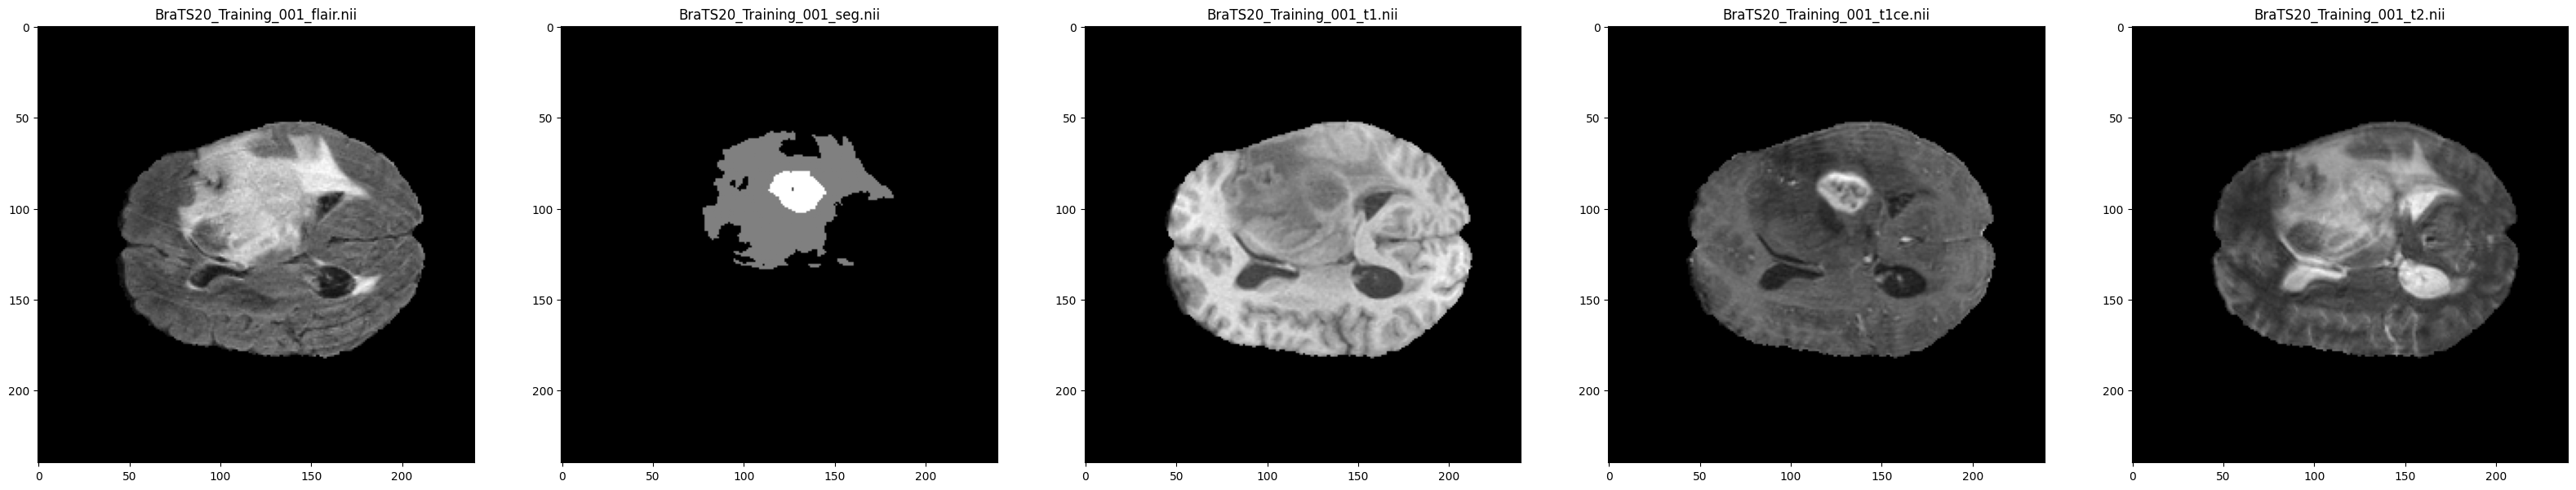

In [7]:
case_dir = p_patients/test_patient
files = list_files(case_dir)
axes = [0]*5
fig, (axes[0],axes[1],axes[2],axes[3],axes[4]) = plt.subplots(1,5,figsize = (40,20))
for i,f in enumerate(files) :
    img, data = load_nifti(f)
    axes[i].imshow(data[:, :, data.shape[2]//2], cmap="gray")
    fname = f.name
    axes[i].set_title(fname)
    inspect_volume(name=fname,nii=img)

#### After exploration, we now create functions to display T1CE and FLAIR and graphical features for our application

In [8]:
class Patient:
    def __init__(self,patient_id,images):
        self.id = patient_id
        self.images = images #dict
    def get_modalities(self):
        return list(self.images.keys())
    def get_image(self,modality):
        return self.images.get(modality)

In [9]:
def load_patients(p_path : Path, sample_percentage : float = 1.0):
    #collect folder only
    patients_folder = [f for f in p_path.iterdir() if f.is_dir()]
    total = len(patients_folder)
    if total == 0 :
        return []
    #validate and get sample size
    if sample_percentage is None :
        sample_percentage = 1.0
    if not(0 < sample_percentage <= 1) :
        raise ValueError("sample_percentage must be in (0, 1].")
    sample_size = max(1,int(sample_percentage*total)) if sample_percentage < 1 else total

    #get patients
    patients = []
    for folder in patients_folder[:sample_size]:
        files = list_files(folder)
        dict_files = {}
        for file in files :
            try :
                dict_files[file.name] = nib.load(str(file))
            except :
                #skip file that's not .nii (nifti)
                continue
        patients.append(Patient(folder.name,dict_files))
    return patients

In [10]:
list_patients = load_patients(p_path = p_patients, sample_percentage = 0.1)

In [11]:
print(len(list_patients))

36


In [32]:
def get_img_by_type(images : dict,typeImg : str):
    fnames = list(images.keys())
    typeImg = typeImg.lower()
    files = []
    for fn in fnames :
        if typeImg in fn.lower() :
            #print(fn)
            files.append((fn,images[fn]))
        #print(fn)
    #t1ce_files = [images[fn] for fn in fnames if "t1ce" in fnames]
    if len(files) == 1 :
        return files[0]
    elif len(files) > 1 :
        raise ValueError(f"Multiple {typeImg}")
    else :
        raise ValueError(f"Missing/Negative {typeImg}")

In [13]:
test_patient = list_patients[0]

In [14]:
test_patient.images["BraTS20_Training_001_t1ce.nii"]

In [16]:
test_patient.images.keys()

dict_keys(['BraTS20_Training_001_flair.nii', 'BraTS20_Training_001_seg.nii', 'BraTS20_Training_001_t1.nii', 'BraTS20_Training_001_t1ce.nii', 'BraTS20_Training_001_t2.nii'])

### Preprocessing pipeline

#### Validate alignment (reject/fix)
    1) Pick a target grid (your canonical space), e.g.:
        spacing: (1, 1, 1) mm
    
        orientation: RAS+
    
        shape: derived after resampling
    
    2) For each dataset:
    
        use the affine to map source voxels → world space
        
        sample that world space onto the target grid

In [34]:
"""
order=0 = nearest neighbor

What it does

Picks the value of the closest source voxel.

No averaging.

Pros

Preserves exact discrete labels (0/1/2/4 stay exactly that).

Fast.

Cons

Blocky edges (“stair steps”).

For images it looks ugly and loses detail.

Use it for
✅ segmentation masks / labels
Because you must not invent label values like 1.7.

order=1 = linear (trilinear in 3D)

What it does

Computes a weighted average of neighboring voxels.

In 3D it mixes up to 8 neighbors (trilinear).

Pros

Smooth, realistic for continuous intensity images.

Good default for MRI intensities.

Cons

Changes values (expected).

If used on masks, it creates fractional labels (bad).

Use it for
✅ MRI images / intensity volumes
"""

def canonicalize_volume(
    image: nib.Nifti1Image,
    order: int = 1, #1 for image, 0 for mask (segmentation)
    template_ref: nib.Nifti1Image | None = None,
):
    """
    1) Reorient to closest canonical (RAS-like) using affine
    2) Resample either:
       - onto a reference grid (sample_ref) using resample_from_to, or
       - to a global voxel spacing (1,1,1) using resample_to_output

    order: interpolation order
      - 1 for images (linear)
      - 0 for masks (nearest)
    """
    out = nib.as_closest_canonical(image)

    if template_ref is not None:
        ref = nib.as_closest_canonical(template_ref)
        out = resample_from_to(out, ref, order=order)
    else:
        out = resample_to_output(out, voxel_sizes=(1.0, 1.0, 1.0), order=order)

    return out

In [37]:
def extract_metadata(image: nib.Nifti1Image, canonical: bool = True,
                     expect_axcodes=('R','A','S'),
                     affine_mismatch_tol: float = 1e-3):
    """
    Inspection helper:
    - Extract metadata (shape/spacing/fov/affine/origin)
    - Emit warnings if header/world-xform looks suspicious
    - Does NOT raise exceptions (inspection only)
    """

    report = {"warnings": [], "ok": True}

    # 1) Basic header codes BEFORE canonical (useful diagnostic)
    qcode0 = int(img.header['qform_code'])
    scode0 = int(img.header['sform_code'])
    ax0 = nib.aff2axcodes(img.affine)

    if qcode0 == 0 and scode0 == 0:
        report["warnings"].append("NO_WORLD_XFORM: qform_code=0 and sform_code=0 (world mapping may be unreliable)")
        report["ok"] = False

    # 2) Optional: check qform vs sform disagreement (only if both exist)
    # (This is a warning, not a failure by itself.)
    if qcode0 > 0 and scode0 > 0:
        qaff = img.get_qform()
        saff = img.get_sform()
        if qaff is not None and saff is not None:
            diff = np.linalg.norm(qaff - saff)
            if diff > affine_mismatch_tol:
                report["warnings"].append(f"QFORM_SFORM_MISMATCH: ||qform-sform||={diff:.4g} (may indicate inconsistent headers)")

    # 3) Canonicalize if requested
    if canonical:
        img_can = nib.as_closest_canonical(img)
    else:
        img_can = img

    shape = img_can.shape[:3]
    spacing = img_can.header.get_zooms()[:3]
    affine = img_can.affine
    origin = affine[:3, 3]
    ax1 = nib.aff2axcodes(affine)
    fov_mm = (np.array(shape, dtype=np.float32) * np.array(spacing, dtype=np.float32)).tolist()

    # 4) After canonical checks
    if canonical and (ax1 != expect_axcodes):
        report["warnings"].append(f"AXCODES_AFTER_CANONICAL_UNEXPECTED: {ax1} (expected {expect_axcodes})")
        # not necessarily fatal, but suspicious
        report["ok"] = False

    # 5) Basic sanity checks
    if any(s <= 0 for s in spacing):
        report["warnings"].append(f"BAD_SPACING: spacing={spacing}")
        report["ok"] = False

    if any(d <= 0 for d in shape):
        report["warnings"].append(f"BAD_SHAPE: shape={shape}")
        report["ok"] = False

    # Pack results
    report.update({
        "shape": tuple(shape),
        "spacing": tuple(spacing),
        "fov_mm": tuple(fov_mm),
        "axcodes_before": ax0,
        "axcodes_after": ax1,
        "origin_mm": tuple(origin.tolist()),
        "affine": affine,
        "qform_code_before": qcode0,
        "sform_code_before": scode0,
    })

    return report

In [67]:
"""
for all patients, extract voxel_size (.get_zooms[:3]), 
shape (.shape[:3]) , 
field of view (FOV in mm) which is calculated by multiplying voxel_size and shape

after that, get mode values for field of view and voxel_size, then compute shape_target.
"""
def compute_spatial_targets(patients : list[Patient]):
    def get_spacingMode(values, step=0.1):
        q = [tuple(round(v/step)*step for v in t) for t in values]
        return Counter(q).most_common(1)[0][0]
    def get_fovMode(fovs_mm, step=5.0):
        q = [tuple(int(round(v/step)*step) for v in f) for f in fovs_mm]
        return Counter(q).most_common(1)[0][0]
    def percentile_triplets(values, p=90):
        arr = np.array(values, dtype=np.float32)   # shape (N,3)
        return tuple(np.percentile(arr, p, axis=0).tolist())
    def shape_from_fov_and_spacing(fov_mm, spacing_mm):
        fov = np.array(fov_mm, dtype=np.float32)
        sp  = np.array(spacing_mm, dtype=np.float32)
        shape = np.ceil(fov / sp).astype(int)
        return tuple(shape.tolist())
    def get_originTarget(spacing:tuple,shape:tuple):
        spacing = np.array(spacing,dtype=np.float32)
        shape = np.array(shape,dtype=np.float32)
        return tuple((-0.5 * spacing * shape).tolist())#require further explaination on this calculation
    list_spacings = []
    list_fovs = []
    origin_target = None
    for patient in patients :
        for fname, image in patient.images.items():
            if not "seg" in fname.lower():
                metadata = extract_metadata(image=image)
                list_spacings.append(metadata["spacing"])
                list_fovs.append(metadata["fov_mm"])
                if origin_target is None :
                    origin_target = metadata["origin_mm"]
    spacingMode = get_spacingMode(list_spacings)
    fovP90 = percentile_triplets(list_fovs, p=90)
    shape_target = shape_from_fov_and_spacing(fovP90, spacingMode)
    #origin_target = get_originTarget(spacing=spacingMode, shape = shape_target)
    assert all(s > 0 for s in spacingMode), "Bad spacing target"
    assert all(n > 0 for n in shape_target), "Bad shape target"
    return {
        "spacing_target" : spacingMode,
        "fov_target" : fovP90,
        "shape_target" : shape_target,
        "origin_target" : origin_target
    }
targets = compute_spatial_targets(patients = list_patients)

In [62]:
targets

{'spacing_target': (1.0, 1.0, 1.0),
 'fov_target': (240.0, 240.0, 155.0),
 'shape_target': (240, 240, 155),
 'origin_target': (-120.0, -120.0, -77.5)}

In [64]:
def get_globalSpatialTemplate(patients : list[Patient]):
    spatialTargets = compute_spatial_targets(patients = patients)
    def make_affineRasTemplate(spacing_target, origin_mm=(0.0,0.0,0.0)):
        affine = np.eye(4,dtype=np.float32)
        affine[0,0] = spacing_target[0]
        affine[1,1] = spacing_target[1]
        affine[2,2] = spacing_target[2]
        affine[:3,3] = np.array(origin_mm,dtype=np.float32)
        return affine
    affine = make_affineRasTemplate(spacing_target = spatialTargets["spacing_target"],
                                   origin_mm = spatialTargets["origin_target"])
    data = np.zeros(spatialTargets["shape_target"], dtype=np.uint8)
    template_ref = nib.Nifti1Image(data,affine)
    return template_ref
template_ref = get_globalSpatialTemplate(patients = list_patients)
print(template_ref)


<class 'nibabel.nifti1.Nifti1Image'>
data shape (240, 240, 155)
affine:
[[   1.     0.     0.  -120. ]
 [   0.     1.     0.  -120. ]
 [   0.     0.     1.   -77.5]
 [   0.     0.     0.     1. ]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : np.bytes_(b'')
db_name         : np.bytes_(b'')
extents         : 0
session_error   : 0
regular         : np.bytes_(b'')
dim_info        : 0
dim             : [  3 240 240 155   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : uint8
bitpix          : 8
slice_start     : 0
pixdim          : [1. 1. 1. 1. 1. 1. 1. 1.]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 0
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : np.bytes_(b'')
aux_file    

In [ ]:
ALLOWED = set(["t1ce","seg","flair"])

In [35]:
def zscore_intensity(
    image: nib.Nifti1Image,
    epsilon: float = 1e-8
):
    #get mask
    data = image.get_fdata(dtype=np.float32)
    data[~np.isfinite(data)] = 0.0

    fg = data != 0
    if not np.any(fg) :
        out = nib.Nifti1Image(data.astype(np.float32), image.affine, header=image.header.copy())
        out.set_data_dtype(np.float32)
        return out

    #compute zscore
    mean = data[fg].mean()
    std = data[fg].std()

    data[fg] = (data[fg] - mean)/(std + epsilon)
    data[~fg] = 0.0
    data = data.astype(np.float32)

    out = nib.Nifti1Image(data,image.affine, header =  image.header.copy())
    out.set_data_dtype(np.float32)
    return out

In [ ]:
def pipeline_0(
    modalities : dict,
    template_ref_bool: bool = False,
    allowed_modality_types : set | None = None
):
    reference_shape_3d = None
    
    preprocessed_modalities = {}        

    template_ref = None
    if template_ref_bool :
        template_patient = Patient(patient_id = "", images = modalities)
        template_ref = get_globalSpatialTemplate(patients = [template_patient])
    
    if not allowed_modality_types is None :
        allowed_modalities = {}
        for typeImg in allowed_modality_types :
            fname,image = get_img_by_type(images=modalities, typeImg=typeImg)
            allowed_modalities[fname] = image
        modalities = allowed_modalities
    for fname,image in modalities.items():
        is_seg = True if "seg" in fname.lower() else False
        interpolation_order = 0 if is_seg else 1
        preprocessed_modalities[fname] = canonicalize_volume(
            image = image,
            order = interpolation_order,
            template_ref = template_ref
        )
        if not is_seg :
            preprocessed_modalities[fname] = normalize_intensity(preprocessed_modalities[fname])
        #check if shape match reference shape (first modal shape)
        if reference_shape_3d is None :
            reference_shape_3d = preprocessed_modalities[fname].shape[:3]#first 3dims
        else :
            if reference_shape_3d != preprocessed_modalities[fname].shape[:3]:
                return { 
                    "preprocessed" : None,
                    "error" : "Unmatched canonicalized shape [:3] within same multimodal"
                       }
        
    return {
        "preprocessed" : preprocessed_modalities,
        "success" : True
    }
    """
    order = 0 if is_seg else 1
    out = canonicalize_volume(
        image = image,
        order = order,
        sample_ref = sample_ref
    )
    if not is_seg :
        out = normalize_intensity(out)
    return out
    """

In [142]:
def normalize_intensity(image: nib.Nifti1Image):
    #extract data and cast to np.float32
    data = image.get_fdata(dtype=np.float32)
    #set all voxels that has inf value to 0
    data[~np.isfinite(data)] = 0.0
    #foreground mask
    #we need mask because we don't want too much background voxels to be included in our calculation which can produce statistical error
    nonzero = data != 0
    if not np.any(nonzero):
        return nib.Nifti1Image(data.astype(np.float32), image.affine, header=image.header.copy())
    #Use only nonzero voxels to compute percentiles
    p1 = np.percentile(data[nonzero], 1)
    mask = (data > p1) & nonzero
    #clip outliers
    lo = np.percentile(data[mask],1)
    hi = np.percentile(data[mask],99)
    data = np.clip(data,lo,hi)
    #Recompute mask after clipping
    p1 = np.percentile(data[nonzero], 1)
    mask = (data > p1) & nonzero
    #apply background = 0
    data[~mask] = 0.0
    data = data.astype(np.float32)
    #wrap back in nifti
    out = nib.Nifti1Image(data, image.affine, header=image.header.copy())
    out.set_data_dtype(np.float32)
    return out

In [85]:
def crop(modalities:dict, margins = (10,10,10), threshold = 0):
    x_mins = []
    x_maxs = []
    y_mins = []
    y_maxs = []
    z_mins = []
    z_maxs = []
    preprocessed_modalities = {}
    for _,image in modalities.items():
        data = np.asanyarray(image.dataobj)
        fg = data > threshold
        if not np.any(fg):
            #nothing to crop
            continue
            #crop_slices = (slice(0,data.shape[0]),slice(0,data.shape[1]),slice(0,data.shape[2]))
            #return data,crop_slices
        xs,ys,zs = np.where(fg)
        mx,my,mz = margins
    
        x_mins.append(max(xs.min() - mx,0))
        x_maxs.append(min(xs.max() + mx + 1,data.shape[0]))
        y_mins.append(max(ys.min() - my,0))
        y_maxs.append(min(ys.max() + my + 1,data.shape[1]))
        z_mins.append(max(zs.min() - mz,0))
        z_maxs.append(min(zs.max() + mz + 1,data.shape[2]))

    if len(x_mins) == len(x_maxs) == len(y_mins) == len(y_maxs) == len(z_mins) == len(z_maxs) == 0 :
        for fname,image in modalities.items():
            data = np.asanyarray(image.dataobj)
            crop_slices = (slice(0,data.shape[0]),slice(0,data.shape[1]),slice(0,data.shape[2]))
            cropped = data[crop_slices]
            new_affine = image.affine.copy()
            cropped_nifti = nib.Nifti1Image(cropped, new_affine, header=image.header.copy())
            preprocessed_modalities[fname] = cropped_nifti
        return preprocessed_modalities,crop_slices
    
    x_min = min(x_mins)
    x_max = max(x_maxs)
    y_min = min(y_mins)
    y_max = max(y_maxs)
    z_min = min(z_mins)
    z_max = max(z_maxs)
    crop_slices = (slice(x_min,x_max),
                   slice(y_min,y_max),
                   slice(z_min,z_max))
    #get reference image to create new affine
    ref_image = None
    for fname, img in modalities.items():
        if "seg" not in fname.lower():
            ref_image = img
            break
    # fallback: if only seg exists, then just use it
    if ref_image is None:
        ref_image = next(iter(modalities.values()))

    ref_image = next(iter(modalities.values()))
    new_affine = ref_image.affine.copy()
    new_affine[:3,3] = (ref_image.affine @ np.array([x_min,y_min,z_min,1.0]))[:3]

    for fname,image in modalities.items():
        data = np.asanyarray(image.dataobj)
        cropped = data[crop_slices]
        cropped_nifti = nib.Nifti1Image(cropped, new_affine, header=image.header.copy())
        preprocessed_modalities[fname] = cropped_nifti

    return preprocessed_modalities,crop_slices

In [86]:
def compute_pad_widths(modalities: dict, target_shape):
    ref_image = None
    for fname, img in modalities.items():
        if "seg" not in fname.lower():
            ref_image = img
            break
    if ref_image is None:
        ref_image = next(iter(modalities.values()))

    current_shape = ref_image.shape[:3]

    pad_widths = []
    for c, t in zip(current_shape, target_shape):
        diff = t - c
        if diff <= 0:
            pad_widths.append((0, 0))
        else:
            left = diff // 2
            right = diff - left
            pad_widths.append((left, right))

    return tuple(pad_widths)

In [89]:
def pipeline_1(
    modalitites : dict,
    is_seg: bool = False,
    z_score_bool: bool = False,
    epsilon: float = 1e-8,
    margins: Tuple[int, int, int] = (10, 10, 10),
    threshold: float = 0,
    target_shape: Tuple[int, int, int] = (160, 160, 128),
    allowed_modality_types : set | None = None
):
    modalities = modalitites

    preprocessed_modalities = {}

    if not allowed_modality_types is None :
        allowed_modalities = {}
        for typeImg in allowed_modality_types :
            fname, image = get_img_by_type(images=modalities, typeImg=typeImg)
            allowed_modalities[fname] = image
        modalities = allowed_modalities

    # z-score (images only)
    if z_score_bool:
        for fname, image in modalities.items():
            if "seg" in fname.lower():
                preprocessed_modalities[fname] = image
            else:
                preprocessed_modalities[fname] = zscore_intensity(image, epsilon=epsilon)
    else:
        preprocessed_modalities = modalities

    # crop (dict -> dict)
    out, crop_slices = crop(preprocessed_modalities, margins=margins, threshold=threshold)

    # shared pad widths from a reference modality inside the dict
    pad_widths = compute_pad_widths(out, target_shape)

    # pad every modality, and update affine translation for left padding
    padded_modalities = {}
    pxL, pyL, pzL = pad_widths[0][0], pad_widths[1][0], pad_widths[2][0]
    shift_vox = np.array([-pxL, -pyL, -pzL, 1.0], dtype=np.float64)

    for fname, img in out.items():
        data = np.asanyarray(img.dataobj)

        padded = np.pad(data, pad_widths, mode="constant", constant_values=0)

        new_affine = img.affine.copy()
        new_affine[:3, 3] = (img.affine @ shift_vox)[:3]

        # keep dtype sensible: float32 for images, keep seg integer-ish
        if "seg" in fname.lower():
            padded_nifti = nib.Nifti1Image(padded, new_affine, header=img.header.copy())
        else:
            padded_nifti = nib.Nifti1Image(padded.astype(np.float32), new_affine, header=img.header.copy())
            padded_nifti.set_data_dtype(np.float32)

        padded_modalities[fname] = padded_nifti

    # build stacked tensor in fixed order: FLAIR then T1CE
    def _find_by_keyword(mods: dict, keyword: str):
        key = keyword.lower()
        for fname, img in mods.items():
            if key in fname.lower():
                return fname, img
        return None, None

    flair_name, flair_img = _find_by_keyword(padded_modalities, "flair")
    t1ce_name, t1ce_img = _find_by_keyword(padded_modalities, "t1ce")

    if flair_img is None or t1ce_img is None:
        meta = {
            "crop_slices": crop_slices,
            "pad_widths": pad_widths,
            "target_shape": target_shape,
            "error": "Missing required modalities for stacking (need FLAIR and T1CE)."
        }
        return None, None, meta

    x_flair = np.asanyarray(flair_img.dataobj).astype(np.float32, copy=False)
    x_t1ce  = np.asanyarray(t1ce_img.dataobj).astype(np.float32, copy=False)

    x = np.stack([x_flair, x_t1ce], axis=0)  # (C, X, Y, Z) with C=2

    # optional seg output
    seg_name, seg_img = _find_by_keyword(padded_modalities, "seg")
    y = None
    if seg_img is not None:
        y = np.asanyarray(seg_img.dataobj)

    meta = {
        "crop_slices": crop_slices,
        "pad_widths": pad_widths,
        "target_shape": target_shape,
        "stack_order": ["flair", "t1ce"],
        "used_files": {"flair": flair_name, "t1ce": t1ce_name, "seg": seg_name},
    }

    return {"x" : x, "y" : y, "meta" : meta}

In [70]:
preproc0_testPatient = pipeline_0(modalities = test_patient.images,
                                  template_ref_bool = True,
                                  allowed_modality_types = ALLOWED)

In [71]:
preproc0_testPatient["preprocessed"]

{'BraTS20_Training_001_t1ce.nii': <nibabel.nifti1.Nifti1Image at 0x14ec00d3d50>,
 'BraTS20_Training_001_seg.nii': <nibabel.nifti1.Nifti1Image at 0x14ec00bcbd0>,
 'BraTS20_Training_001_flair.nii': <nibabel.nifti1.Nifti1Image at 0x14ebfdc0190>}

In [49]:
def show_montage(
    data,
    remove_background=True,
    crop=None,
    rotate_angle=90,
    is_seg = False,
    title = ""
):
    """
    Display a seamless montage of slices using skimage.util.montage.

    Parameters
    ----------
    data : np.ndarray
        3D array (H, W, Slices)
    remove_background : bool
        Apply percentile clipping (1–99%) to improve contrast.
    crop : tuple or None
        Optional cropping along the first axis, e.g. (50, -50).
    rotate_angle : float
        Angle to rotate the final montage (e.g., 90).
    cmap : str
        Matplotlib colormap.
    """
    cmap="gray" if not is_seg else "inferno"
    if crop is not None:
        start, end = crop
        data = data[start:end, :, :]

    # Background removal
    if remove_background:
        p1, p99 = np.percentile(data, (1, 99))
        data = np.clip(data, p1, p99)

    # skimage expects (N, H, W)
    slices = np.transpose(data, (2, 0, 1))

    # Create seamless montage
    canvas = montage(
        slices,
        grid_shape=None,
        padding_width=0,
        fill=0
    )

    # Rotate for correct orientationx
    canvas = rotate(canvas, rotate_angle, resize=True)
    facecolor = "black" if not is_seg else "black"
    alpha = 1.0 if not is_seg else 0.5
    # Display
    plt.figure(figsize=(10, 10),facecolor=facecolor)
    plt.imshow(canvas, cmap=cmap)
    plt.axis("off")
    plt.title(f"{title}",color="white")
    plt.show()
#show_montage(data=test)

In [101]:
test_pipeline_0 = pipeline_0(test_patient.image!s,allowed=ALLOWED)

In [50]:
def display_preprocessed(preprocessed_images : dict):
    for fname,image in preprocessed_images.items() :
        is_seg = True if "seg" in fname.lower() else False
        inspect_volume(name=fname, nii = image)
        show_montage(data = image.dataobj, title = fname,is_seg=is_seg)


[BraTS20_Training_001_t1ce.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 786.0
  mean/std: 60.70083236694336 153.2816619873047
  unique (mask-ish check): [  0. 259. 260. 261. 262. 263. 264. 265. 266. 267.]


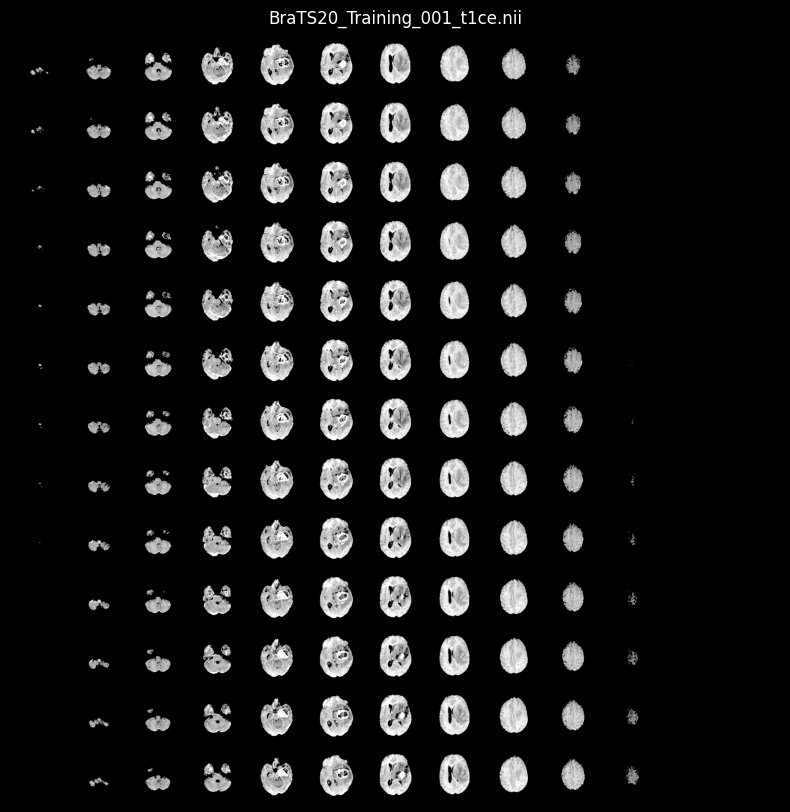


[BraTS20_Training_001_seg.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 4.0
  mean/std: 0.05197121575474739 0.35266146063804626
  unique (mask-ish check): [0. 1. 2. 4.]


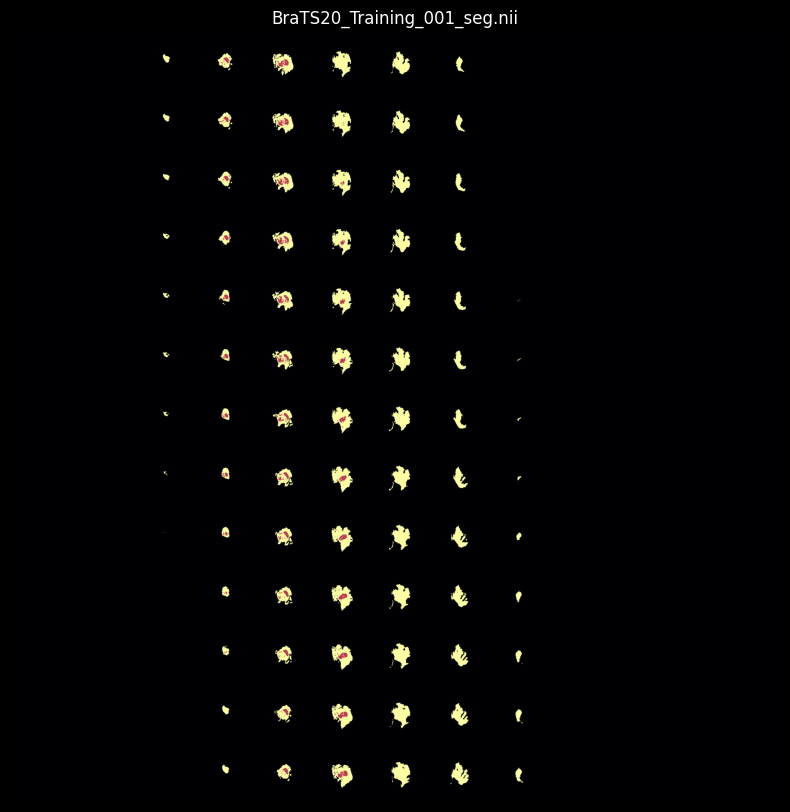


[BraTS20_Training_001_flair.nii]
  shape: (240, 240, 155)
  spacing(mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  dtype: float32
  min/max: 0.0 377.0
  mean/std: 25.290149688720703 66.48786163330078
  unique (mask-ish check): [  0. 103. 104. 105. 106. 107. 108. 109. 110. 111.]


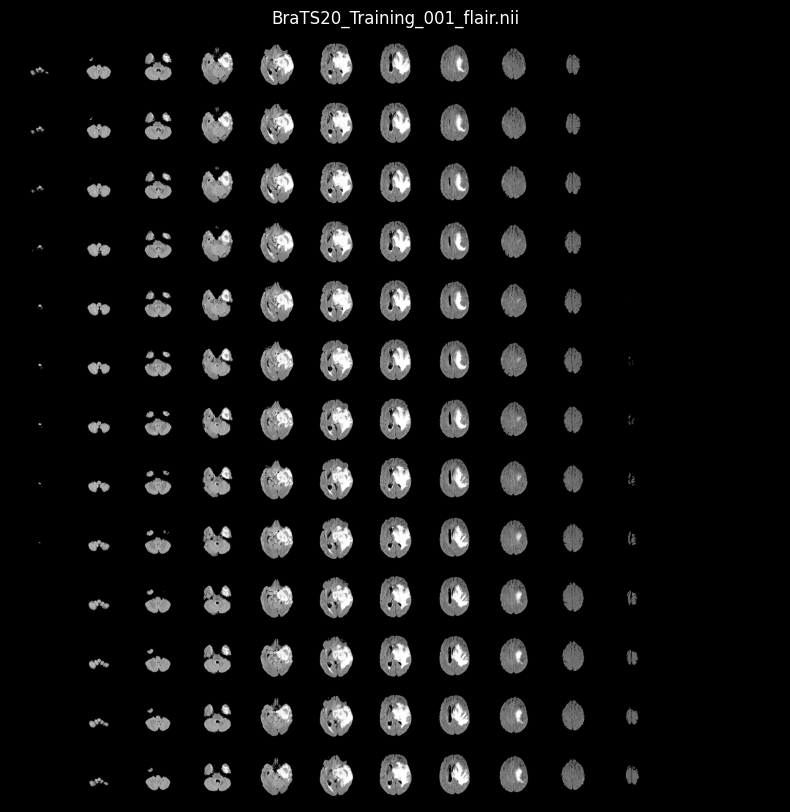

In [74]:
display_preprocessed(preproc0_testPatient["preprocessed"])

In [82]:
    def display_preprocessed_overlay(
        preprocessed_images: dict,
        seg_key: str | None = None,
        alpha: float = 0.5,
        rotate_angle: float = 90,
        clip_percentiles: tuple = (1, 99)
    ):
        # find segmentation
        if seg_key is None:
            seg_items = [(k, v) for k, v in preprocessed_images.items() if "seg" in k.lower()]
            if len(seg_items) != 1:
                raise ValueError("Could not uniquely find seg image. Pass seg_key explicitly.")
            seg_name, seg_img = seg_items[0]
        else:
            seg_name, seg_img = seg_key, preprocessed_images[seg_key]
    
        seg = np.asanyarray(seg_img.dataobj)
        # montage for seg
        seg_slices = np.transpose(seg, (2, 0, 1))
        seg_canvas = montage(seg_slices, grid_shape=None, padding_width=0, fill=0)
        # rotate seg with nearest-neighbor to keep labels
        seg_canvas = rotate(seg_canvas, rotate_angle, resize=True, order=0, preserve_range=True)
        seg_canvas = np.rint(seg_canvas).astype(np.int16)
    
        # RGBA overlay (BraTS labels: 1,2,4)
        overlay = np.zeros(seg_canvas.shape + (4,), dtype=np.float32)
        overlay[seg_canvas == 1] = (1.0, 0.0, 0.0, alpha)  # red
        overlay[seg_canvas == 2] = (0.0, 1.0, 0.0, alpha)  # green
        overlay[seg_canvas == 4] = (1.0, 1.0, 0.0, alpha)  # yellow
        # fallback: if labels are different, make any nonzero red
        if overlay[..., 3].max() == 0:
            overlay[seg_canvas > 0] = (1.0, 0.0, 0.0, alpha)
    
        for fname, img in preprocessed_images.items():
            if fname == seg_name:
                continue
    
            data = np.asanyarray(img.dataobj)
            slices = np.transpose(data, (2, 0, 1))
            base = montage(slices, grid_shape=None, padding_width=0, fill=0)
            base = rotate(base, rotate_angle, resize=True, order=1, preserve_range=True)
    
            if clip_percentiles is not None:
                p1, p99 = np.percentile(base, clip_percentiles)
                base = np.clip(base, p1, p99)
    
            plt.figure(figsize=(10, 10), facecolor="black")
            plt.imshow(base, cmap="gray")
            plt.imshow(overlay)
            plt.title(f"{fname} + {seg_name}", color="white")
            plt.axis("off")
            plt.show()


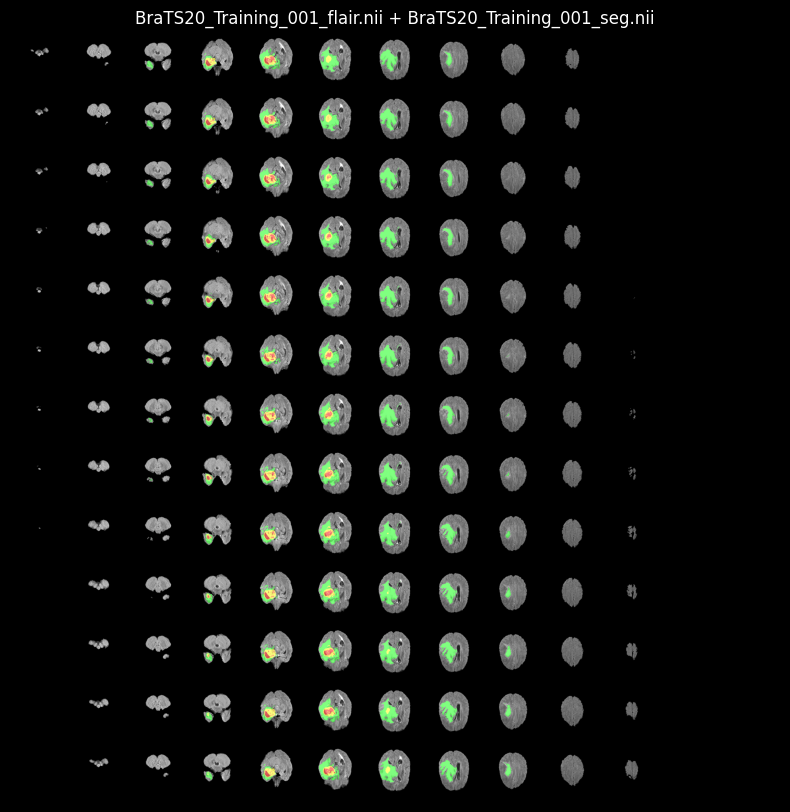

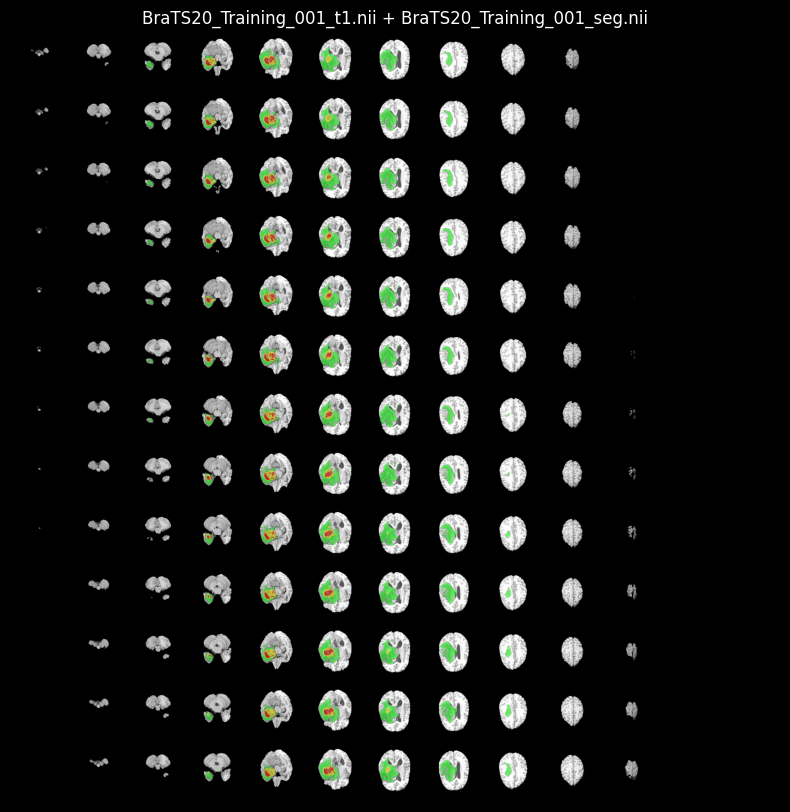

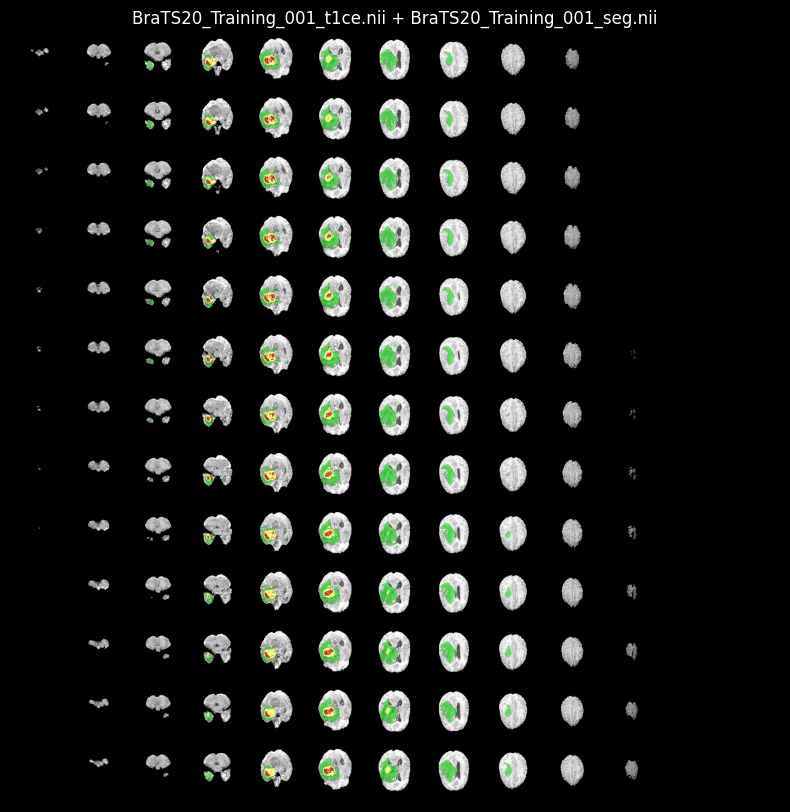

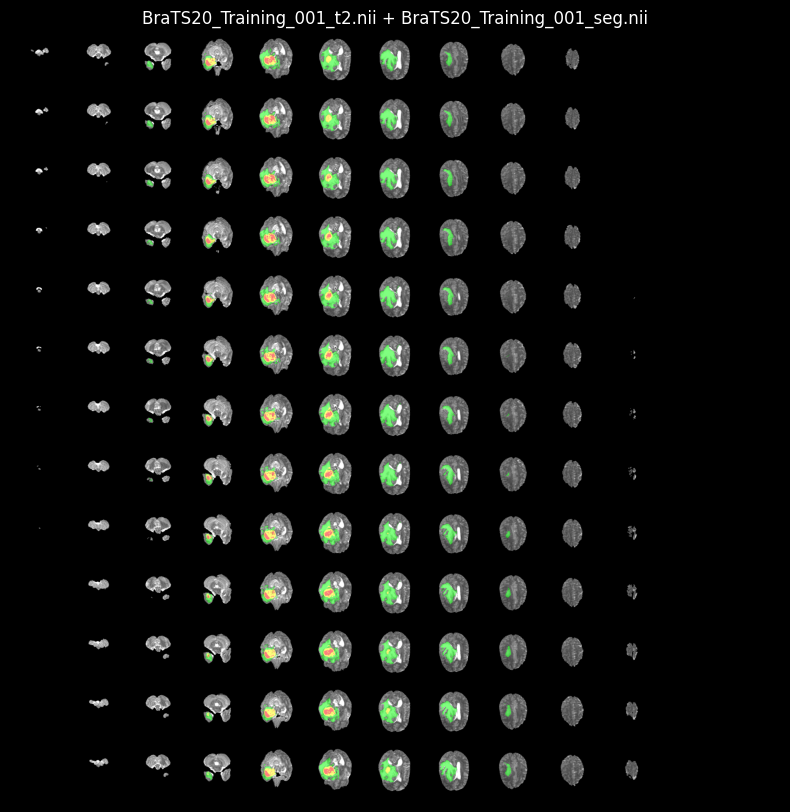

In [88]:
display_preprocessed_overlay(test_patient.images)

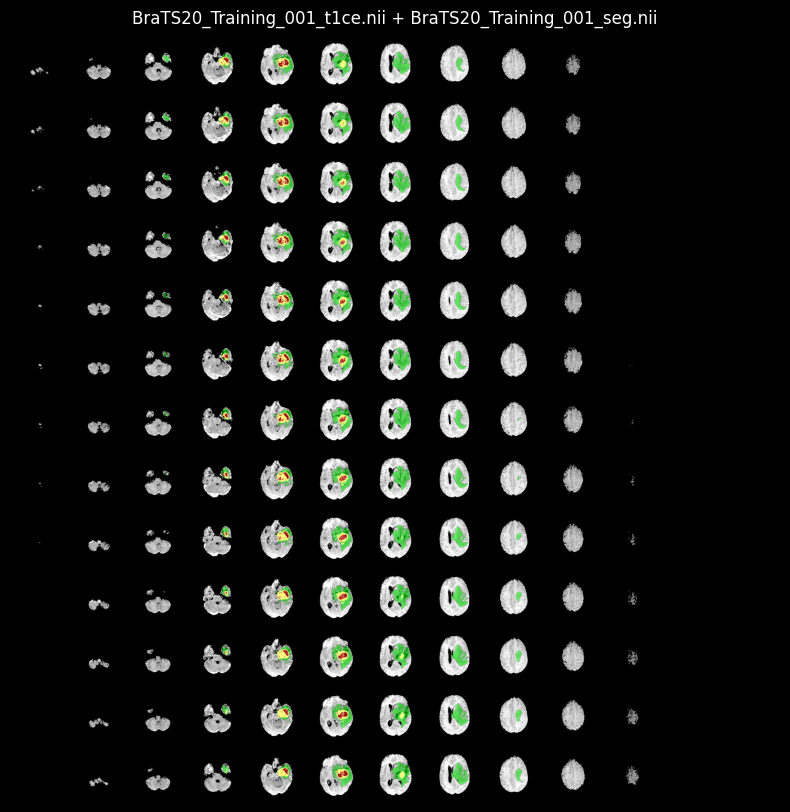

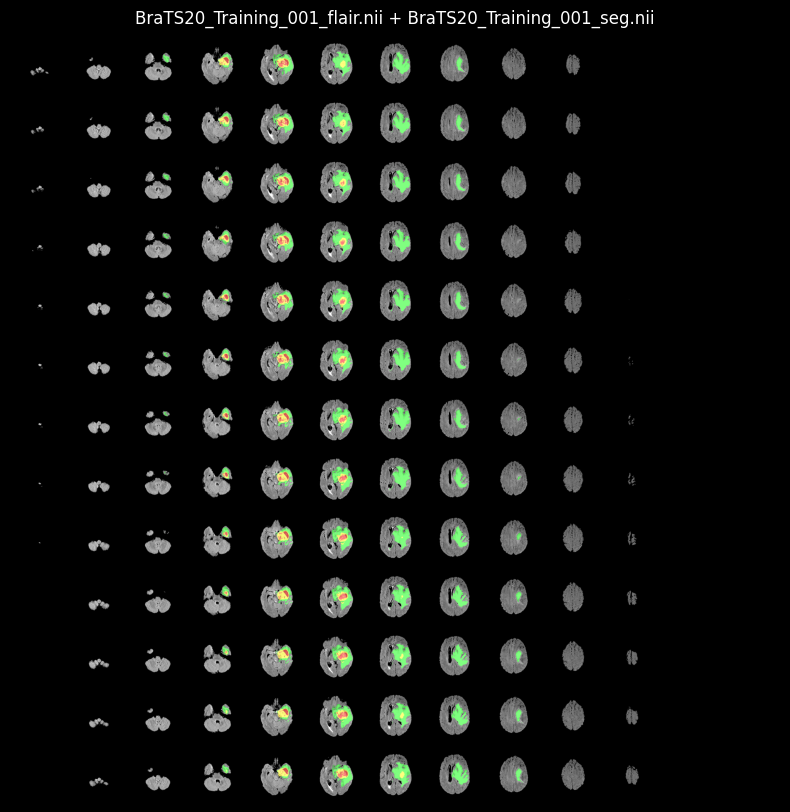

In [84]:
display_preprocessed_overlay(preproc0_testPatient["preprocessed"])

In [106]:

def visualize_pipeline1(
    x: np.ndarray,
    y: np.ndarray | None = None,
    axis: str = "z",                 # "x", "y", or "z"
    slice_idx: int | None = None,
    modality: str | int = "flair",   # "flair" | "t1ce" | 0 | 1
    overlay: str = "contour",        # "contour" or "mask"
    alpha: float = 0.35,
    title: str | None = None
):
    """
    Visualize pipeline_1 output with optional segmentation overlay.

    x: (C, X, Y, Z) where C=2 in order [FLAIR, T1CE]
    y: (X, Y, Z) integer labels (0 background). Optional.
    axis: which slicing axis to view
    slice_idx: which slice index; if None, choose a reasonable default
    modality: which channel to show ("flair"->0, "t1ce"->1)
    overlay:
      - "contour": outlines of y>0 (and optionally class contours)
      - "mask": filled overlay of y>0
    """

    assert x.ndim == 4, f"x must be 4D (C,X,Y,Z). Got shape {x.shape}"
    C, X, Ydim, Z = x.shape
    assert C >= 1, "x must have at least one channel"

    # resolve modality index
    if isinstance(modality, str):
        m = modality.lower()
        if m == "flair":
            c = 0
        elif m == "t1ce":
            c = 1
        else:
            raise ValueError("modality must be 'flair', 't1ce', 0, or 1")
    else:
        c = int(modality)
    if c < 0 or c >= C:
        raise ValueError(f"Invalid modality index {c} for C={C}")

    # axis index
    axis = axis.lower()
    axis_to_dim = {"x": 1, "y": 2, "z": 3}  # dims in x: (C, X, Y, Z)
    if axis not in axis_to_dim:
        raise ValueError("axis must be one of 'x', 'y', 'z'")
    dim = axis_to_dim[axis]

    img = x[c].astype(np.float32, copy=False)

    # choose slice if not provided
    if slice_idx is None:
        if y is not None and np.any(y > 0):
            # pick the slice (along chosen axis) with maximum tumor pixels
            counts = []
            if axis == "x":
                for i in range(X):
                    counts.append(np.count_nonzero(y[i, :, :] > 0))
            elif axis == "y":
                for i in range(Ydim):
                    counts.append(np.count_nonzero(y[:, i, :] > 0))
            else:  # "z"
                for i in range(Z):
                    counts.append(np.count_nonzero(y[:, :, i] > 0))
            slice_idx = int(np.argmax(counts))
        else:
            # middle slice
            slice_idx = (img.shape[dim - 1] // 2) if axis != "x" else (X // 2)

    # extract 2D slice
    if axis == "x":
        img2d = img[slice_idx, :, :]
        seg2d = None if y is None else y[slice_idx, :, :]
    elif axis == "y":
        img2d = img[:, slice_idx, :]
        seg2d = None if y is None else y[:, slice_idx, :]
    else:  # "z"
        img2d = img[:, :, slice_idx]
        seg2d = None if y is None else y[:, :, slice_idx]

    # plot
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img2d, cmap="gray")
    ax.axis("off")

    if seg2d is not None:
        seg2d = np.asarray(seg2d)
        if overlay == "mask":
            # overlay any tumor (y>0)
            mask = (seg2d > 0).astype(np.float32)
            ax.imshow(mask, alpha=alpha)  # default colormap is fine; it's just a mask overlay
        elif overlay == "contour":
            # outline y>0
            ax.contour((seg2d > 0).astype(np.uint8), levels=[0.5], linewidths=1.5)

            # if multi-class, outline each label too (1,2,3,4...)
            labels = [l for l in np.unique(seg2d) if l != 0]
            for l in labels:
                ax.contour((seg2d == l).astype(np.uint8), levels=[0.5], linewidths=1.0)
        else:
            raise ValueError("overlay must be 'contour' or 'mask'")

    if title is None:
        mod_name = "flair" if c == 0 else "t1ce"
        title = f"{mod_name.upper()} | axis={axis} | slice={slice_idx}"
    ax.set_title(title)

    plt.tight_layout()
    return fig, ax

In [143]:
preproc_1_testPatient = pipeline_1(preproc0_testPatient["preprocessed"])
preproc_1_testPatient["meta"]

{'crop_slices': (slice(np.int64(44), np.int64(201), None),
  slice(np.int64(15), np.int64(206), None),
  slice(0, np.int64(149), None)),
 'pad_widths': ((1, 2), (0, 0), (0, 0)),
 'target_shape': (160, 160, 128),
 'stack_order': ['flair', 't1ce'],
 'used_files': {'flair': 'BraTS20_Training_001_flair.nii',
  't1ce': 'BraTS20_Training_001_t1ce.nii',
  'seg': 'BraTS20_Training_001_seg.nii'}}

In [144]:
testDict = {"flair" : preproc_1_testPatient["x"][0],
            "t1ce" : preproc_1_testPatient["x"][1],
            "seg" : preproc_1_testPatient["y"]}

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'T1CE | axis=z | slice=67'}>)

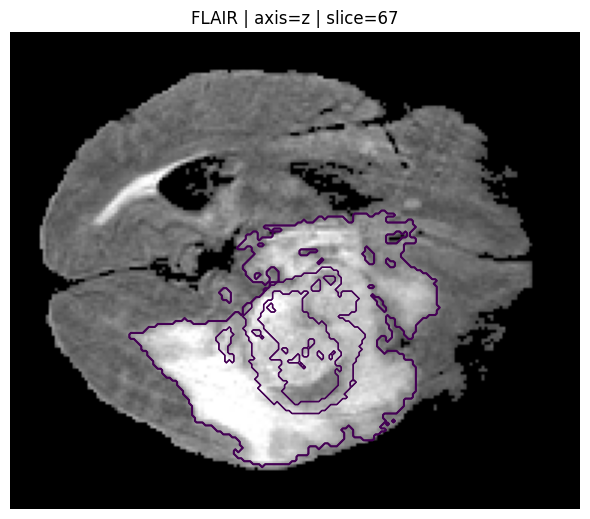

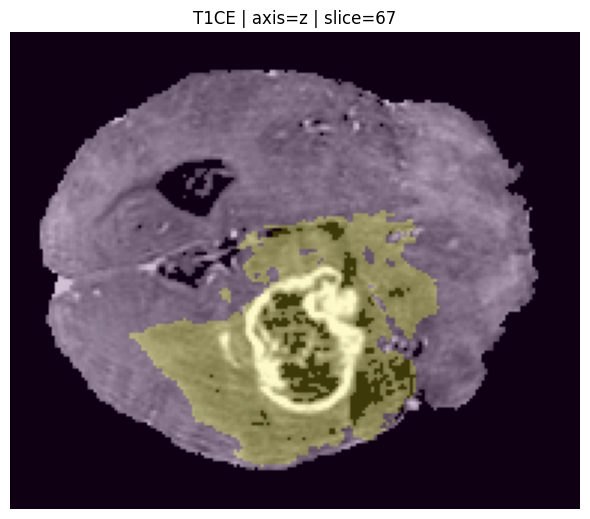

In [145]:
visualize_pipeline1(x=preproc_1_testPatient["x"], y=testDict["seg"], axis="z", modality="flair", overlay="contour")
visualize_pipeline1(x=preproc_1_testPatient["x"], y=testDict["seg"], axis="z", modality="t1ce", overlay="mask", alpha=0.25)

In [146]:
np.unique(testDict["seg"])

array([0, 1, 2, 4], dtype=uint8)